In [3]:
import os
import pandas as pd
import urllib.request
from pymatgen.core import Structure
from sklearn.model_selection import train_test_split

print("1. Loading Matbench dataset...")
file_path = r"C:\Btech\SEM5\cuda\data_driven\matbench_mp_e_form.json\mp_e_form.json"
df = pd.read_json(file_path, orient="split")

print("2. Subsampling 130,000 structures...")
df_subset = df.sample(n=130000, random_state=42).reset_index(drop=True)

print("3. Splitting into Train (80k), Val (10k), Test (10k), Test2 (30k)...")

train_df, temp_df = train_test_split(df_subset, test_size=50000, random_state=42)

test2_df, temp2_df = train_test_split(temp_df, test_size=20000, random_state=42)

val_df, test_df = train_test_split(temp2_df, test_size=0.50, random_state=42)

def generate_folder(dataframe, folder_name):
    os.makedirs(folder_name, exist_ok=True)
    id_prop_list = []
    print(f"Generating {len(dataframe)} files in '{folder_name}'...")
    
    for index, row in dataframe.iterrows():
        struct_dict = row['structure']
        structure = Structure.from_dict(struct_dict)
        material_id = f"mat_{index}"
        cif_filename = os.path.join(folder_name, f"{material_id}.cif")
        structure.to(fmt="cif", filename=cif_filename)
        id_prop_list.append([material_id, row['e_form']])
        
    pd.DataFrame(id_prop_list).to_csv(os.path.join(folder_name, "id_prop.csv"), index=False, header=False)
    
    atom_init_url = "https://raw.githubusercontent.com/txie-93/cgcnn/master/data/sample-regression/atom_init.json"
    urllib.request.urlretrieve(atom_init_url, os.path.join(folder_name, "atom_init.json"))

# Execute the generation
base_dir = "cgcnn_dataset"
generate_folder(train_df, os.path.join(base_dir, "train_data"))
generate_folder(val_df, os.path.join(base_dir, "val_data"))
generate_folder(test_df, os.path.join(base_dir, "test_data"))
generate_folder(test2_df, os.path.join(base_dir, "test2"))

print("Data generation complete!")

1. Loading Matbench dataset...
2. Subsampling 130,000 structures...
3. Splitting into Train (80k), Val (10k), Test (10k), Test2 (30k)...
Generating 80000 files in 'cgcnn_dataset\train_data'...
Generating 10000 files in 'cgcnn_dataset\val_data'...
Generating 10000 files in 'cgcnn_dataset\test_data'...
Generating 30000 files in 'cgcnn_dataset\test2'...
Data generation complete!


In [4]:
import subprocess
import sys
import re

print("Starting CGCNN Training.")

python_executable = sys.executable
process = subprocess.Popen(
    [python_executable, "-u", "-W", "ignore", "main.py", "cgcnn_dataset", "--epochs", "20", "--batch-size", "256"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

current_epoch = 0
current_train_mae = 0.0
total_epochs = 20

with open("training_log.txt", "w") as log_file:
    for line in process.stdout:
        log_file.write(line)
        
        train_match = re.search(r'Epoch: \[(\d+)\].*MAE \d+\.\d+ \((\d+\.\d+)\)', line)
        if train_match:
            current_epoch = int(train_match.group(1)) + 1 
            current_train_mae = float(train_match.group(2))
            
        val_match = re.search(r'\* MAE (\d+\.\d+)', line)
        r2_match = re.search(r'R2 (\d+\.\d+)', line)
        
        if val_match:
            val_mae = float(val_match.group(1))
            
            r2_str = ""
            if r2_match:
                r2_str = f" | R²: {float(r2_match.group(1)):.4f}"
            
            print(f"Epoch {current_epoch:02d}/{total_epochs} | Train MAE: {current_train_mae:.4f} eV/atom | Val MAE: {val_mae:.4f} eV/atom{r2_str}")

process.wait()
print("\nTraining complete! The best model is safely saved as 'model_best.pth.tar'.")

Starting CGCNN Training.
Epoch 01/20 | Train MAE: 0.2780 eV/atom | Val MAE: 0.1865 eV/atom | R²: 0.9473
Epoch 02/20 | Train MAE: 0.1950 eV/atom | Val MAE: 0.1658 eV/atom | R²: 0.9582
Epoch 03/20 | Train MAE: 0.1750 eV/atom | Val MAE: 0.1604 eV/atom | R²: 0.9671
Epoch 04/20 | Train MAE: 0.1560 eV/atom | Val MAE: 0.1313 eV/atom | R²: 0.9745
Epoch 05/20 | Train MAE: 0.1520 eV/atom | Val MAE: 0.1142 eV/atom | R²: 0.9799
Epoch 06/20 | Train MAE: 0.1400 eV/atom | Val MAE: 0.1153 eV/atom | R²: 0.9798
Epoch 07/20 | Train MAE: 0.1320 eV/atom | Val MAE: 0.1395 eV/atom | R²: 0.9744
Epoch 08/20 | Train MAE: 0.1320 eV/atom | Val MAE: 0.0957 eV/atom | R²: 0.9850
Epoch 09/20 | Train MAE: 0.1270 eV/atom | Val MAE: 0.0926 eV/atom | R²: 0.9868
Epoch 10/20 | Train MAE: 0.1250 eV/atom | Val MAE: 0.0905 eV/atom | R²: 0.9866
Epoch 11/20 | Train MAE: 0.1180 eV/atom | Val MAE: 0.0995 eV/atom | R²: 0.9852
Epoch 12/20 | Train MAE: 0.1170 eV/atom | Val MAE: 0.1001 eV/atom | R²: 0.9844
Epoch 13/20 | Train MAE: 0.

In [6]:
import warnings
warnings.filterwarnings('ignore') 

import torch
import pandas as pd
from torch.utils.data import DataLoader
from cgcnn.data import CIFData, collate_pool
from cgcnn.model import CrystalGraphConvNet

print("1. Loading Test Dataset...")
test_dataset = CIFData('cgcnn_dataset/test_data')
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, collate_fn=collate_pool)

print("2. Loading Trained Model...")
# Load the saved model weights 
checkpoint = torch.load(r'C:\Btech\SEM5\cuda\data_driven\model_best.pth.tar', map_location='cuda', weights_only=False)

# Extract the original architecture settings
model_args = checkpoint['args']
structures, _, _ = test_dataset[0]
orig_atom_fea_len = structures[0].shape[-1]
nbr_fea_len = structures[1].shape[-1]

# Rebuild the empty PyTorch model architecture
model = CrystalGraphConvNet(
    orig_atom_fea_len, nbr_fea_len,
    atom_fea_len=model_args['atom_fea_len'],
    n_conv=model_args['n_conv'],
    h_fea_len=model_args['h_fea_len'],
    n_h=model_args['n_h'],
    classification=False
)

# Inject your trained weights into the model
model.load_state_dict(checkpoint['state_dict'])
model.cuda()
model.eval()

# Build a Normalizer to convert the raw neural network output back into eV/atom
class Normalizer(object):
    def __init__(self, tensor):
        self.mean = torch.mean(tensor)
        self.std = torch.std(tensor)
    def load_state_dict(self, state_dict):
        # FIX: Force the mean and std to be on the CPU so they match the output
        self.mean = state_dict['mean'].cpu()
        self.std = state_dict['std'].cpu()
    def denorm(self, x):
        return x * self.std + self.mean

normalizer = Normalizer(torch.zeros(3))
normalizer.load_state_dict(checkpoint['normalizer'])

print("3. Running  Predictions on Unseen Data...")
test_targets = []
test_preds = []
test_cif_ids = []

with torch.no_grad(): 
    for i, (input, target, batch_cif_ids) in enumerate(test_loader):
        
        # Move inputs to GPU memory
        input_var = (input[0].cuda(), input[1].cuda(), input[2].cuda(), [crys_idx.cuda() for crys_idx in input[3]])
        
        # Make the prediction
        output = model(*input_var)
        
        # Un-normalize the prediction to get the real energy value
        pred = normalizer.denorm(output.data.cpu())
        
        # Store the results
        test_targets.extend(target.view(-1).tolist())
        test_preds.extend(pred.view(-1).tolist())
        test_cif_ids.extend(batch_cif_ids)

# 4. Save results to CSV 
results_df = pd.DataFrame({
    'cif_id': test_cif_ids,
    'target': test_targets,
    'prediction': test_preds
})
results_df.to_csv('test_results.csv', index=False, header=False)

print("Success! Testing loop complete and 'test_results.csv' is ready.")

1. Loading Test Dataset...
2. Loading Trained Model...
3. Running  Predictions on Unseen Data...
Success! Testing loop complete and 'test_results.csv' is ready.


Parsing training logs and calculating final metrics...

       FINAL TEST SET METRICS
Mean Absolute Error (MAE):  0.0771 eV/atom
Root Mean Squared (RMSE):   0.1198 eV/atom
Max Absolute Error:         1.5748 eV/atom
R-squared (R²) Score:       0.9896



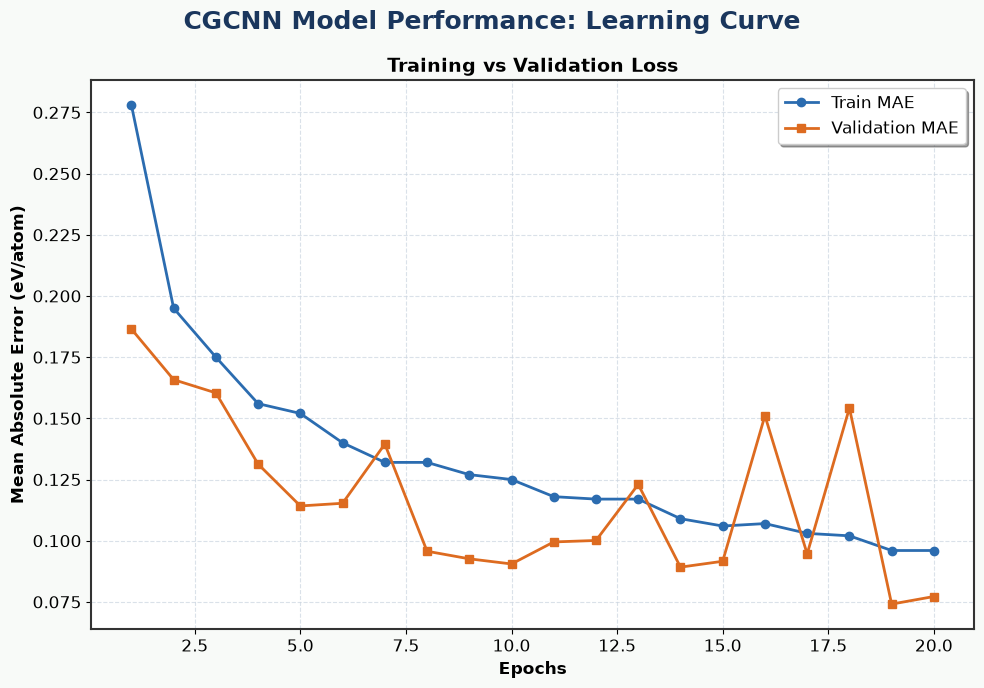

   ACTUAL VS PREDICTED (TOP 15 SAMPLES)


,Material ID,Actual (eV),Predicted (eV),Error (eV)
0,mat_121748,-0.8859,-0.8401,0.0458
1,mat_123712,-1.0533,-1.0718,0.0185
2,mat_99793,-0.8691,-0.9173,0.0482
3,mat_33261,-0.0430,0.0372,0.0802
4,mat_113267,0.4712,0.4760,0.0048
5,mat_89210,-0.4122,-0.3557,0.0565
6,mat_114285,-0.2082,-0.2053,0.0029
7,mat_66221,-0.3339,-0.4200,0.0862
8,mat_89688,-0.1964,-0.0104,0.1860
9,mat_61435,-0.3340,-0.2974,0.0366


In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Parsing training logs and calculating final metrics...\n")

train_mae_history = []
val_mae_history = []
current_epoch_train = []

try:
    with open("training_log.txt", "r") as f:
        lines = f.readlines()

    for line in lines:
        # Grab Training MAE
        if "Epoch:" in line and "MAE" in line:
            match = re.search(r'MAE \d+\.\d+ \((\d+\.\d+)\)', line)
            if match:
                current_epoch_train.append(float(match.group(1)))
                
        # Grab Validation MAE explicitly using regex
        val_match = re.search(r'\* MAE (\d+\.\d+)', line)
        if val_match:
            val_mae = float(val_match.group(1))
            val_mae_history.append(val_mae)
            if current_epoch_train:
                train_mae_history.append(current_epoch_train[-1])
                current_epoch_train = []
except FileNotFoundError:
    print("Warning: 'training_log.txt' not found. Learning curve will be empty.")


# 2. LOAD TEST PREDICTIONS & CALCULATE METRICS
results = pd.read_csv("test_results.csv", header=None, names=["Material_ID", "True_Energy", "Predicted_Energy"])
results["Error"] = results["Predicted_Energy"] - results["True_Energy"]
results["Abs_Error"] = results["Error"].abs()

# Calculate comprehensive metrics
mae = mean_absolute_error(results["True_Energy"], results["Predicted_Energy"])
mse = mean_squared_error(results["True_Energy"], results["Predicted_Energy"])
rmse = np.sqrt(mse)
r2 = r2_score(results["True_Energy"], results["Predicted_Energy"])
max_error = results["Abs_Error"].max()

print("       FINAL TEST SET METRICS")
print("==========================================")
print(f"Mean Absolute Error (MAE):  {mae:.4f} eV/atom")
print(f"Root Mean Squared (RMSE):   {rmse:.4f} eV/atom")
print(f"Max Absolute Error:         {max_error:.4f} eV/atom")
print(f"R-squared (R²) Score:       {r2:.4f}")
print("==========================================\n")


# 3. CREATE THE CUSTOMIZED DASHBOARD (SINGLE PLOT)
# Set global style parameters for a professional look
plt.rcParams.update({
    'font.size': 12,
    'axes.linewidth': 1.5,
    'axes.edgecolor': '#333333',
    'axes.labelweight': 'bold',
    'figure.facecolor': "#F8FAF8"
})

fig, ax1 = plt.subplots(figsize=(10, 7))
fig.suptitle('CGCNN Model Performance: Learning Curve', fontsize=18, fontweight='bold', color='#1A365D')

# --- Plot 1: Learning Curve ---
if train_mae_history and val_mae_history:
    epochs = range(1, len(train_mae_history) + 1)
    ax1.plot(epochs, train_mae_history, label='Train MAE', color='#2B6CB0', marker='o', linewidth=2, markersize=6)
    ax1.plot(epochs, val_mae_history, label='Validation MAE', color='#DD6B20', marker='s', linewidth=2, markersize=6)
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Mean Absolute Error (eV/atom)')
    ax1.set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
    ax1.legend(frameon=True, shadow=True)
    ax1.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')
else:
    ax1.text(0.5, 0.5, 'Log data not available', ha='center', va='center')

plt.tight_layout()
plt.show()

print("   ACTUAL VS PREDICTED (TOP 15 SAMPLES)")
display_df = results[['Material_ID', 'True_Energy', 'Predicted_Energy', 'Abs_Error']].copy()
display_df.columns = ['Material ID', 'Actual (eV)', 'Predicted (eV)', 'Error (eV)']

try:
    display(display_df.head(15).round(4))
except NameError:
    print(display_df.head(15).round(4).to_string(index=False))

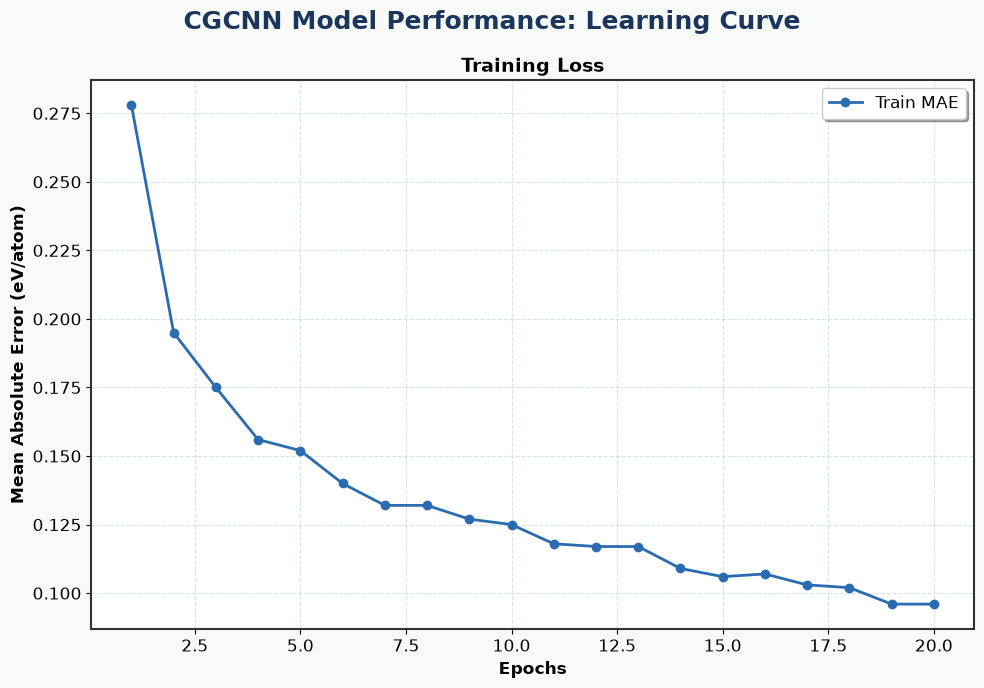

   ACTUAL VS PREDICTED (TOP 15 SAMPLES)


,Material ID,Actual (eV),Predicted (eV),Error (eV)
0,mat_121748,-0.8859,-0.8401,0.0458
1,mat_123712,-1.0533,-1.0718,0.0185
2,mat_99793,-0.8691,-0.9173,0.0482
3,mat_33261,-0.0430,0.0372,0.0802
4,mat_113267,0.4712,0.4760,0.0048
5,mat_89210,-0.4122,-0.3557,0.0565
6,mat_114285,-0.2082,-0.2053,0.0029
7,mat_66221,-0.3339,-0.4200,0.0862
8,mat_89688,-0.1964,-0.0104,0.1860
9,mat_61435,-0.3340,-0.2974,0.0366


In [2]:
# 3. CREATE THE CUSTOMIZED DASHBOARD (SINGLE PLOT)
# Set global style parameters for a professional look
plt.rcParams.update({
    'font.size': 12,
    'axes.linewidth': 1.5,
    'axes.edgecolor': '#333333',
    'axes.labelweight': 'bold',
    'figure.facecolor': "#F8FAF8"
})

fig, ax1 = plt.subplots(figsize=(10, 7))
fig.suptitle('CGCNN Model Performance: Learning Curve', fontsize=18, fontweight='bold', color='#1A365D')

# --- Plot 1: Learning Curve (Train Only) ---
if train_mae_history:
    epochs = range(1, len(train_mae_history) + 1)
    
    # Plot ONLY the Training MAE (Blue line)
    ax1.plot(epochs, train_mae_history, label='Train MAE', color='#2B6CB0', marker='o', linewidth=2, markersize=6)
    
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Mean Absolute Error (eV/atom)')
    ax1.set_title('Training Loss', fontsize=14, fontweight='bold')
    ax1.legend(frameon=True, shadow=True)
    ax1.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')
else:
    ax1.text(0.5, 0.5, 'Log data not available', ha='center', va='center')

plt.tight_layout()
plt.show()

print("   ACTUAL VS PREDICTED (TOP 15 SAMPLES)")
display_df = results[['Material_ID', 'True_Energy', 'Predicted_Energy', 'Abs_Error']].copy()
display_df.columns = ['Material ID', 'Actual (eV)', 'Predicted (eV)', 'Error (eV)']

try:
    display(display_df.head(15).round(4))
except NameError:
    print(display_df.head(15).round(4).to_string(index=False))

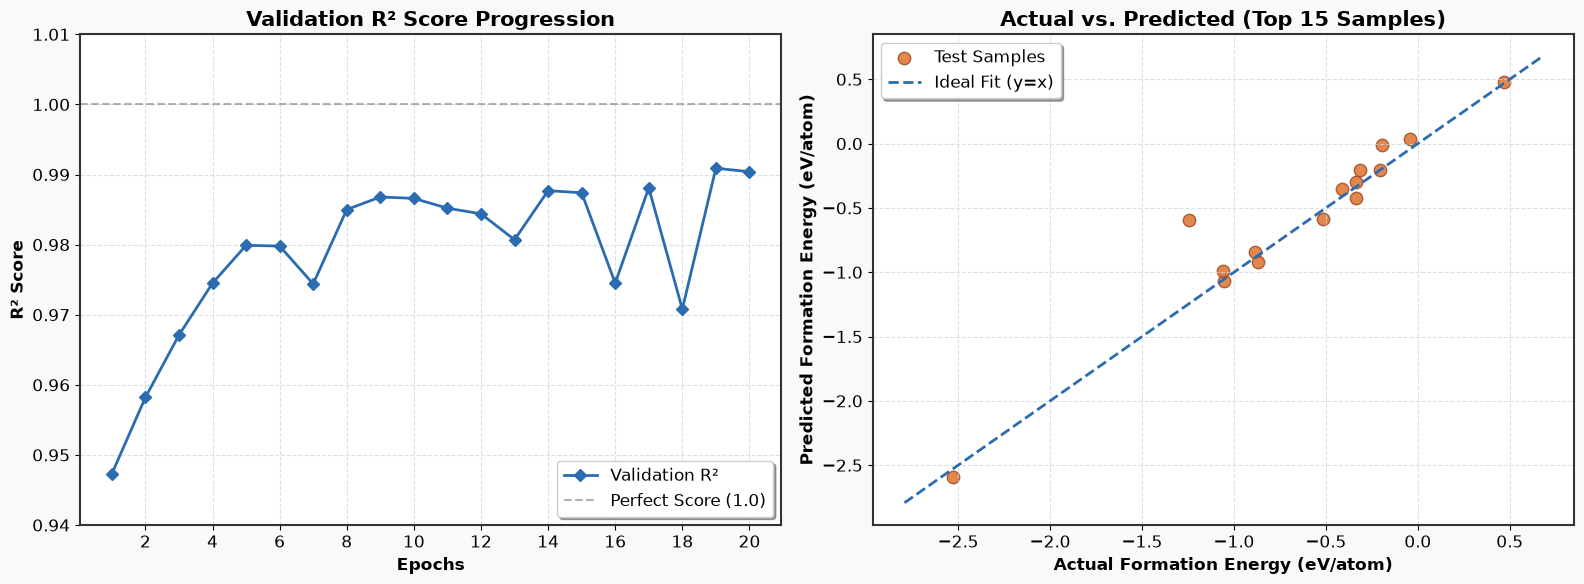

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Data Extracted from your logs
epochs = np.arange(1, 21)
val_r2 = [0.9473, 0.9582, 0.9671, 0.9745, 0.9799, 0.9798, 0.9744, 0.9850, 0.9868, 0.9866,
          0.9852, 0.9844, 0.9807, 0.9877, 0.9874, 0.9745, 0.9881, 0.9708, 0.9909, 0.9904]

# 15 Samples Data
actual_ev = [-0.8859, -1.0533, -0.8691, -0.0430, 0.4712, -0.4122, -0.2082, -0.3339, 
             -0.1964, -0.3340, -2.5299, -1.0593, -1.2441, -0.5137, -0.3126]
predicted_ev = [-0.8401, -1.0718, -0.9173, 0.0372, 0.4760, -0.3557, -0.2053, -0.4200, 
                -0.0104, -0.2974, -2.5917, -0.9910, -0.5935, -0.5828, -0.2026]

# Global styling
plt.rcParams.update({
    'font.size': 12,
    'axes.linewidth': 1.5,
    'axes.edgecolor': '#333333',
    'axes.labelweight': 'bold',
    'figure.facecolor': "#F8FAF8"
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Validation R² Progression ---
ax1.plot(epochs, val_r2, color='#2B6CB0', marker='D', linewidth=2, markersize=6, label='Validation R²')
ax1.axhline(y=1.0, color='gray', linestyle='--', alpha=0.6, label='Perfect Score (1.0)')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('R² Score')
ax1.set_title('Validation R² Score Progression', fontsize=15, fontweight='bold')
ax1.set_ylim(0.94, 1.01)
ax1.set_xticks(range(2, 21, 2))
ax1.legend(frameon=True, shadow=True, loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')

# --- Plot 2: Actual vs Predicted Scatter Plot ---
ax2.scatter(actual_ev, predicted_ev, color='#DD6B20', edgecolor='#9C4221', s=80, alpha=0.8, label='Test Samples')

# Create the 45-degree ideal line
min_val = min(min(actual_ev), min(predicted_ev)) - 0.2
max_val = max(max(actual_ev), max(predicted_ev)) + 0.2
ax2.plot([min_val, max_val], [min_val, max_val], color='#2B6CB0', linestyle='--', linewidth=2, label='Ideal Fit (y=x)')

ax2.set_xlabel('Actual Formation Energy (eV/atom)')
ax2.set_ylabel('Predicted Formation Energy (eV/atom)')
ax2.set_title('Actual vs. Predicted (Top 15 Samples)', fontsize=15, fontweight='bold')
ax2.legend(frameon=True, shadow=True)
ax2.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')

plt.tight_layout()
plt.show()

<h3> Testing with 5k samples </h3>

In [8]:
import warnings
warnings.filterwarnings('ignore') 

import torch
import pandas as pd
import random
from torch.utils.data import DataLoader, Subset
from cgcnn.data import CIFData, collate_pool
from cgcnn.model import CrystalGraphConvNet

print("1. Loading Test2 Dataset...")
test_dataset = CIFData('cgcnn_dataset/test2')

# Subsample exactly 5000 structures for a faster test
print("2. Randomly subsampling 5000 structures...")
indices = random.sample(range(len(test_dataset)), 5000)
test_dataset_5k = Subset(test_dataset, indices)

test_loader = DataLoader(test_dataset_5k, batch_size=256, shuffle=False, collate_fn=collate_pool)

print("3. Loading Trained Model...")
checkpoint = torch.load(r'C:\Btech\SEM5\cuda\data_driven\model_best.pth.tar', map_location='cuda', weights_only=False)

model_args = checkpoint['args']
structures, _, _ = test_dataset[0]
orig_atom_fea_len = structures[0].shape[-1]
nbr_fea_len = structures[1].shape[-1]

model = CrystalGraphConvNet(
    orig_atom_fea_len, nbr_fea_len,
    atom_fea_len=model_args['atom_fea_len'],
    n_conv=model_args['n_conv'],
    h_fea_len=model_args['h_fea_len'],
    n_h=model_args['n_h'],
    classification=False
)

model.load_state_dict(checkpoint['state_dict'])
model.cuda()
model.eval()

class Normalizer(object):
    def __init__(self, tensor):
        self.mean = torch.mean(tensor)
        self.std = torch.std(tensor)
    def load_state_dict(self, state_dict):
        self.mean = state_dict['mean'].cpu()
        self.std = state_dict['std'].cpu()
    def denorm(self, x):
        return x * self.std + self.mean

normalizer = Normalizer(torch.zeros(3))
normalizer.load_state_dict(checkpoint['normalizer'])

print("4. Running GPU Predictions on 5k Samples...")
test_targets = []
test_preds = []
test_cif_ids = []

with torch.no_grad(): 
    for i, (input, target, batch_cif_ids) in enumerate(test_loader):
        input_var = (input[0].cuda(), input[1].cuda(), input[2].cuda(), [crys_idx.cuda() for crys_idx in input[3]])
        output = model(*input_var)
        pred = normalizer.denorm(output.data.cpu())
        
        test_targets.extend(target.view(-1).tolist())
        test_preds.extend(pred.view(-1).tolist())
        test_cif_ids.extend(batch_cif_ids)

# Save results to a specific test2 CSV
results_df = pd.DataFrame({
    'cif_id': test_cif_ids,
    'target': test_targets,
    'prediction': test_preds
})
results_df.to_csv('test2_results.csv', index=False, header=False)

print("Success! Testing loop complete and 'test2_results.csv' is ready.")

1. Loading Test2 Dataset...
2. Randomly subsampling 5000 structures...
3. Loading Trained Model...
4. Running GPU Predictions on 5k Samples...
Success! Testing loop complete and 'test2_results.csv' is ready.


Parsing training logs and calculating final metrics for Test2...

       FINAL TEST2 SET METRICS (5K samples)       
Mean Absolute Error (MAE):  0.0777 eV/atom
Root Mean Squared (RMSE):   0.1193 eV/atom
Max Absolute Error:         1.1152 eV/atom
R-squared (R²) Score:       0.9895



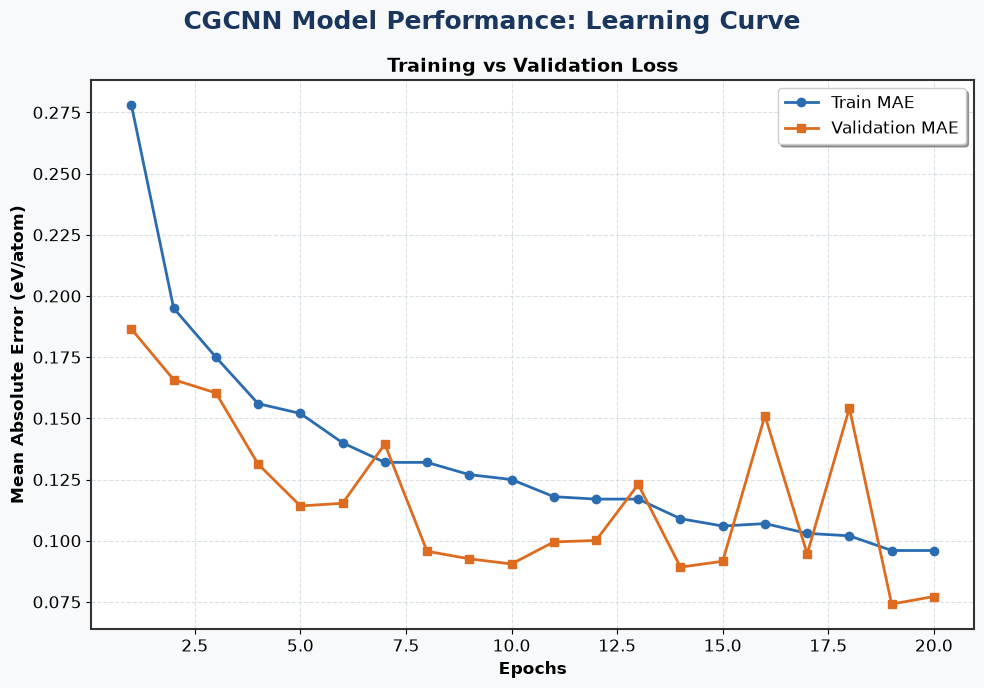

   ACTUAL VS PREDICTED (TOP 15 SAMPLES)


,Material ID,Actual (eV),Predicted (eV),Error (eV)
0,mat_63912,-3.3480,-3.3827,0.0347
1,mat_351,-0.0596,0.1125,0.1722
2,mat_61070,-2.0620,-2.1316,0.0696
3,mat_125524,-1.1787,-1.1952,0.0165
4,mat_61841,-0.4257,-0.4730,0.0473
5,mat_95867,-2.8954,-2.8541,0.0413
6,mat_103608,-1.8517,-1.8196,0.0321
7,mat_83823,-1.6554,-1.6824,0.0270
8,mat_72425,-2.3314,-2.3751,0.0437
9,mat_54243,-1.6872,-1.7328,0.0455


In [15]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Parsing training logs and calculating final metrics for Test2...\n")

# 1. PARSE TRAINING LOGS (For the Loss Graph)
train_mae_history = []
val_mae_history = []
current_epoch_train = []

try:
    with open("training_log.txt", "r") as f:
        lines = f.readlines()

    for line in lines:
        if "Epoch:" in line and "MAE" in line:
            match = re.search(r'MAE \d+\.\d+ \((\d+\.\d+)\)', line)
            if match:
                current_epoch_train.append(float(match.group(1)))
                
        val_match = re.search(r'\* MAE (\d+\.\d+)', line)
        if val_match:
            val_mae = float(val_match.group(1))
            val_mae_history.append(val_mae)
            if current_epoch_train:
                train_mae_history.append(current_epoch_train[-1])
                current_epoch_train = []
except FileNotFoundError:
    print("Warning: 'training_log.txt' not found. Learning curve will be empty.")

# 2. LOAD TEST2 PREDICTIONS & CALCULATE METRICS
results = pd.read_csv("test2_results.csv", header=None, names=["Material_ID", "True_Energy", "Predicted_Energy"])
results["Error"] = results["Predicted_Energy"] - results["True_Energy"]
results["Abs_Error"] = results["Error"].abs()

mae = mean_absolute_error(results["True_Energy"], results["Predicted_Energy"])
mse = mean_squared_error(results["True_Energy"], results["Predicted_Energy"])
rmse = np.sqrt(mse)
r2 = r2_score(results["True_Energy"], results["Predicted_Energy"])
max_error = results["Abs_Error"].max()

print("       FINAL TEST2 SET METRICS (5K samples)       ")
print(f"Mean Absolute Error (MAE):  {mae:.4f} eV/atom")
print(f"Root Mean Squared (RMSE):   {rmse:.4f} eV/atom")
print(f"Max Absolute Error:         {max_error:.4f} eV/atom")
print(f"R-squared (R²) Score:       {r2:.4f}")
print("==========================================\n")

plt.rcParams.update({
    'font.size': 12,
    'axes.linewidth': 1.5,
    'axes.edgecolor': '#333333',
    'axes.labelweight': 'bold',
    'figure.facecolor': '#F8F9FA'
})

fig, ax1 = plt.subplots(figsize=(10, 7))
fig.suptitle('CGCNN Model Performance: Learning Curve', fontsize=18, fontweight='bold', color='#1A365D')

if train_mae_history and val_mae_history:
    epochs = range(1, len(train_mae_history) + 1)
    ax1.plot(epochs, train_mae_history, label='Train MAE', color='#2B6CB0', marker='o', linewidth=2, markersize=6)
    ax1.plot(epochs, val_mae_history, label='Validation MAE', color='#DD6B20', marker='s', linewidth=2, markersize=6)
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Mean Absolute Error (eV/atom)')
    ax1.set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
    ax1.legend(frameon=True, shadow=True)
    ax1.grid(True, linestyle='--', alpha=0.7, color='#CBD5E0')
else:
    ax1.text(0.5, 0.5, 'Log data not available', ha='center', va='center')

plt.tight_layout()
plt.show()

print("   ACTUAL VS PREDICTED (TOP 15 SAMPLES)")

display_df = results[['Material_ID', 'True_Energy', 'Predicted_Energy', 'Abs_Error']].copy()
display_df.columns = ['Material ID', 'Actual (eV)', 'Predicted (eV)', 'Error (eV)']

try:
    display(display_df.head(15).round(4))
except NameError:
    print(display_df.head(15).round(4).to_string(index=False))